In [2]:
from get_data.get_data import get_competitions

get_competitions()

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
0,38,235,Poland,Ekstraklasa,male,False,False,2022/2023,2022-11-14T23:52:05.742598,2022-11-15T02:59:44.768676,2022-11-14T17:48:38.809568,2022-11-14T23:52:05.742598
1,38,108,Poland,Ekstraklasa,male,False,False,2021/2022,2022-05-23T03:43:06.359171,2022-08-20T22:30:40.451963,2022-08-20T22:30:40.451963,2022-05-23T03:43:06.359171
2,38,90,Poland,Ekstraklasa,male,False,False,2020/2021,2021-08-25T19:54:02.119299,2022-08-16T20:44:23.378841,None,2021-08-25T19:54:02.119299
3,38,42,Poland,Ekstraklasa,male,False,False,2019/2020,2022-11-10T20:52:27.485478,2021-06-13T16:17:31.694,None,2022-11-10T20:52:27.485478
4,38,4,Poland,Ekstraklasa,male,False,False,2018/2019,2021-08-27T11:26:39.802832,2021-06-13T16:17:31.694,None,2020-07-29T05:00
5,55,43,Europe,UEFA Euro,male,False,True,2020,2022-02-01T17:20:34.319496,2022-08-04T12:00,2022-08-04T12:00,2022-02-01T17:20:34.319496


In [3]:
from get_data.get_data import get_matches

get_matches(55, 43)

,match_id,match_date,kick_off,competition,season,home_team,away_team,home_score,away_score,attendance,...,last_updated_360,match_week,competition_stage,stadium,referee,home_managers,away_managers,data_version,shot_fidelity_version,xy_fidelity_version
0,3795220,2021-07-06,21:00:00.000,Europe - UEFA Euro,2020,Italy,Spain,1,1,NaN,...,2022-08-04T12:00,6,Semi-finals,Wembley Stadium,Felix Brych,Roberto Mancini,Luis Enrique Martínez García,1.1.0,2,2
1,3788769,2021-06-21,21:00:00.000,Europe - UEFA Euro,2020,Russia,Denmark,1,4,23644.0,...,2022-08-04T12:00,3,Group Stage,Parken,Clément Turpin,Stanislav Cherchesov,Kasper Hjulmand,1.1.0,2,2
2,3788761,2021-06-18,15:00:00.000,Europe - UEFA Euro,2020,Sweden,Slovakia,1,0,11525.0,...,2022-08-04T12:00,2,Group Stage,Saint-Petersburg Stadium,Daniel Siebert,Jan Olof Andersson,Štefan Tarkovič,1.1.0,2,2
3,3788766,2021-06-20,18:00:00.000,Europe - UEFA Euro,2020,Italy,Wales,1,0,11541.0,...,2022-08-04T12:00,3,Group Stage,Estadio Olímpico,Ovidiu Alin Hațegan,,,1.1.0,2,2
4,3788764,2021-06-19,18:00:00.000,Europe - UEFA Euro,2020,Portugal,Germany,2,4,12926.0,...,2022-08-04T12:00,2,Group Stage,Allianz Arena,Anthony Taylor,Fernando Manuel Fernandes da Costa Santos,Joachim Löw,1.1.0,2,2
5,3788773,2021-06-23,21:00:00.000,Europe - UEFA Euro,2020,Portugal,France,2,2,NaN,...,2022-08-04T12:00,3,Group Stage,Puskás Aréna,Antonio Miguel Mateu Lahoz,Fernando Manuel Fernandes da Costa Santos,Didier Deschamps,1.1.0,2,2
6,3788755,2021-06-16,18:00:00.000,Europe - UEFA Euro,2020,Turkey,Wales,0,2,19762.0,...,2022-08-04T12:00,2,Group Stage,Bakı Olimpiya Stadionu,Artur Manuel Ribeiro Soares Dias,,,1.1.0,2,2
7,3788754,2021-06-16,21:00:00.000,Europe - UEFA Euro,2020,Italy,Switzerland,3,0,12445.0,...,2022-08-04T12:00,2,Group Stage,Estadio Olímpico,Sergey Karasev,Roberto Mancini,Vladimir Petković,1.1.0,2,2
8,3788762,2021-06-19,21:00:00.000,Europe - UEFA Euro,2020,Spain,Poland,1,1,NaN,...,2022-08-04T12:00,2,Group Stage,Estadio de La Cartuja,Daniele Orsato,Luis Enrique Martínez García,Paulo Manuel Carvalho de Sousa,1.1.0,2,2
9,3788760,2021-06-18,18:00:00.000,Europe - UEFA Euro,2020,Croatia,Czech Republic,1,1,5607.0,...,2022-08-04T12:00,2,Group Stage,Hampden Park,Carlos del Cerro Grande,Zlatko Dalić,Jaroslav Šilhavý,1.1.0,2,2


* passes - podania
* carrys - prowadzenie piłki
* ball_receipts - odbiory piłki
* duels - pojedynki
* dribbles - drybling
* blocks - zablokowanie piłki
* clearances - wybicie piłki
* dispossesseds - przechwyt piłki
* errors - błędy
* foul_committeds - popełniony faul
* foul_wons - foul przeciwnika
* half_ends - koniec połowy
* injury_stoppages - przerwa kontuzyjna
* interceptions - przechwyt
* miscontrols - nieopanowanie piłki
* shots - strzały

In [4]:
from get_data.get_data import get_merged_events

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

In [5]:
def correction_perspective_location(eventDataFrame):
    start_team = [team for team in eventDataFrame['possession_team'].values][0]
    new_start_locations = [[abs(120.0 - float(location[0])), abs(80.0 - float(location[1]))] if team != start_team and location != '' else location for location,team in zip(eventDataFrame['location'].values, eventDataFrame['possession_team'].values)]
    
    newEventDataFrame = eventDataFrame
    newEventDataFrame['location'] = new_start_locations
    return newEventDataFrame

merged_events = correction_perspective_location(merged_events)

In [6]:
from grid_areas.grid_areas import get_event_area

def add_areas_and_pos_merged_events(eventDataFrame, areas_x = 12, areas_y = 8):
    start_team = [team for team in eventDataFrame['possession_team'].values][0]
    
    event_start_locations = [[value[0], value[1]] if value != '' else '' for value in eventDataFrame['location'].values]
    event_end_locations = [[value['end_location'][0], value['end_location'][1]] if value != '' and 'end_location' in value.keys() else '' for value in eventDataFrame['event'].values]

    event_end_locations = [[abs(120.0 - float(location[0])), abs(80.0 - float(location[1]))] if team != start_team and location != '' else location for location, team in zip(event_end_locations, eventDataFrame['possession_team'].values)]

    event_start_areas = [get_event_area(location, areas_x, areas_y) if location != '' else '' for location in event_start_locations]
    event_end_areas = [get_event_area(location, areas_x, areas_y) if location != '' else '' for location in event_end_locations]

    event_area_codes = [f'{a}{b}' for a,b in zip(event_start_areas, event_end_areas)]
    newEventDataFrame = eventDataFrame

    newEventDataFrame['start_x'] = [value[0] if value != '' else '' for value in event_start_locations]
    newEventDataFrame['start_y'] = [value[1] if value != '' else '' for value in event_start_locations]

    newEventDataFrame['end_x'] = [value[0] if value != '' else '' for value in event_end_locations]
    newEventDataFrame['end_y'] = [value[1] if value != '' else '' for value in event_end_locations]

    newEventDataFrame['start_area'] = event_start_areas
    newEventDataFrame['end_area'] = event_end_areas
    newEventDataFrame['area_code'] = event_area_codes

    return newEventDataFrame

In [7]:
merged_events = add_areas_and_pos_merged_events(merged_events)

In [8]:
from sequences.get_sequences import get_event_sequences

sequences = get_event_sequences(merged_events)

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

def draw_pitch(ax, areas_x, areas_y, scale=1):
    # size of the pitch is 120, 80
    
    X = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T']
    Y = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]

    #Pitch Outline & Centre Line
    plt.plot([0,0],[0,80*scale], color="black")
    plt.plot([0,120*scale],[80*scale,80*scale], color="black")
    plt.plot([120*scale,120*scale],[80*scale,0], color="black")
    plt.plot([120*scale,0],[0,0], color="black")
    plt.plot([60*scale,60*scale],[0,80*scale], color="black")
    
    for i in range (0,areas_x):
        plt.text((((60/areas_x)+i*120/areas_x)-1)*scale, 82*scale, X[i], fontdict=None, fontsize = 8*scale)
        
    for i in range (0,areas_y):
        plt.text(-3*scale, (((40/areas_y)+i*80/areas_y)-1)*scale, Y[i], fontdict=None, fontsize = 8*scale)

    #Left Penalty Area
    plt.plot([14.6*scale,14.6*scale],[57.8*scale,22.2*scale],color="black")
    plt.plot([0,14.6*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([0,14.6*scale],[22.2*scale,22.2*scale],color="black")

    #Right Penalty Area
    plt.plot([120*scale,105.4*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([105.4*scale,105.4*scale],[57.8*scale,22.5*scale],color="black")
    plt.plot([120*scale, 105.4*scale],[22.5*scale,22.5*scale],color="black")

    #Left 6-yard Box
    plt.plot([0,4.9*scale],[48*scale,48*scale],color="black")
    plt.plot([4.9*scale,4.9*scale],[48*scale,32*scale],color="black")
    plt.plot([0,4.9*scale],[32*scale,32*scale],color="black")

    #Right 6-yard Box
    plt.plot([120*scale,115.1*scale],[48*scale,48*scale],color="black")
    plt.plot([115.1*scale,115.1*scale],[48*scale,32*scale],color="black")
    plt.plot([120*scale,115.1*scale],[32*scale,32*scale],color="black")
    
    #Sectors
    for i in range(1, areas_y):
        plt.plot([120*scale,0],[(80/areas_y)*i*scale,(80/areas_y)*i*scale], color="gray")

    for i in range(1, areas_x):
        plt.plot([(120/areas_x)*i*scale,(120/areas_x)*i*scale],[80*scale,0], color="gray")
    
    #Prepare Circles
    centreCircle = plt.Circle((60*scale,40*scale),8.1*scale,color="black",fill=False)
    centreSpot = plt.Circle((60*scale,40*scale),0.71,color="black")
    leftPenSpot = plt.Circle((9.7*scale,40*scale),0.71,color="black")
    rightPenSpot = plt.Circle((110.3*scale,40*scale),0.71,color="black")

    #Draw Circles
    ax.add_patch(centreCircle)
    ax.add_patch(centreSpot)
    ax.add_patch(leftPenSpot)
    ax.add_patch(rightPenSpot)

def draw_events_sequence2(sequence, start_team, areas_x, areas_y, scale):
    if areas_x < 2:
        areas_x = 2
    if areas_y < 2:
        areas_y = 2
    if scale < 1:
        scale = 1

    fig, ax = plt.subplots()
    fig.set_size_inches(7*scale, 5*scale)
    i = 0
    team = [team for team in sequence['possession_team']][0]
    player = ''
    
    print(f'Team: {team}')

    for index, row in sequence.iterrows():
        if player != row['player']:
            player = row['player']
            i+=1
        
        type = row['type']
        timespamp = row['timestamp']
            
        print(f'{i}: {player} ({type}) <{timespamp}>')

        if row['possession_team'] == start_team and row['team'] == start_team:
            general_color = 'blue'
        else:
            general_color = 'red'

        match row['type']:
            case 'Ball Receipt*':
                plt.plot(float(row['start_x']*scale), float(row['start_y']*scale), marker='.',
                markersize=32, markeredgecolor=general_color, markerfacecolor=general_color)
                plt.plot(float(row['start_x']*scale), float(row['start_y']*scale), marker='o',
                markersize=32, markeredgecolor=general_color, markerfacecolor="black")
            case 'Duel':
                plt.plot(float(row['start_x']*scale), float(row['start_y']*scale), marker='v',
                markersize=32, markeredgecolor=general_color, markerfacecolor=general_color)
            case 'Pass':
                plt.plot([float(row['start_x']*scale), float(row['end_x']*scale)],
                [float(row['start_y']*scale),float(row['end_y']*scale)], color=general_color, linewidth=4.0)
                plt.plot(float(row['start_x']*scale), float(row['start_y']*scale), marker='o',
                markersize=32, markeredgecolor=general_color, markerfacecolor="black")
            case 'Carry':
                plt.plot([float(row['start_x']*scale), float(row['end_x']*scale)],
                [float(row['start_y']*scale),float(row['end_y']*scale)], color='green', linewidth=4.0)
            case 'Dispossessed':
                plt.plot(float(row['start_x']*scale), float(row['start_y']*scale), marker='s',
                markersize=32, markeredgecolor=general_color, markerfacecolor=general_color)
            case 'Shot':
                plt.plot([float(row['start_x']*scale), float(row['end_x']*scale)],
                [float(row['start_y']*scale),float(row['end_y']*scale)], color='yellow', linewidth=4.0)
                plt.plot(float(row['start_x']*scale), float(row['start_y']*scale), marker='o',
                markersize=32, markeredgecolor=general_color, markerfacecolor="black")
            case _:
                plt.plot(float(row['start_x']*scale), float(row['start_y']*scale), marker='1',
                markersize=32, markeredgecolor=general_color, markerfacecolor="black")
            
        plt.text(float(row['start_x']*scale)-2, float(row['start_y']*scale)-2, str(i),
        color='white', fontsize=16)

    draw_pitch(ax, areas_x, areas_y, scale)
    plt.show()

In [10]:
sequences[3].to_csv("test.csv", encoding="utf-8", index=False)

Sequence: 1
Team: Sweden
1: Sebastian Larsson (Pass) <00:00:00.080>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:00:01.502>
2: Victor Nilsson Lindelöf (Carry) <00:00:01.502>
2: Victor Nilsson Lindelöf (Pass) <00:00:02.653>
3: Mikael Lustig (Ball Receipt*) <00:00:05.863>
3: Mikael Lustig (Pass) <00:00:05.863>
4: Robin Quaison (Ball Receipt*) <00:00:09.353>


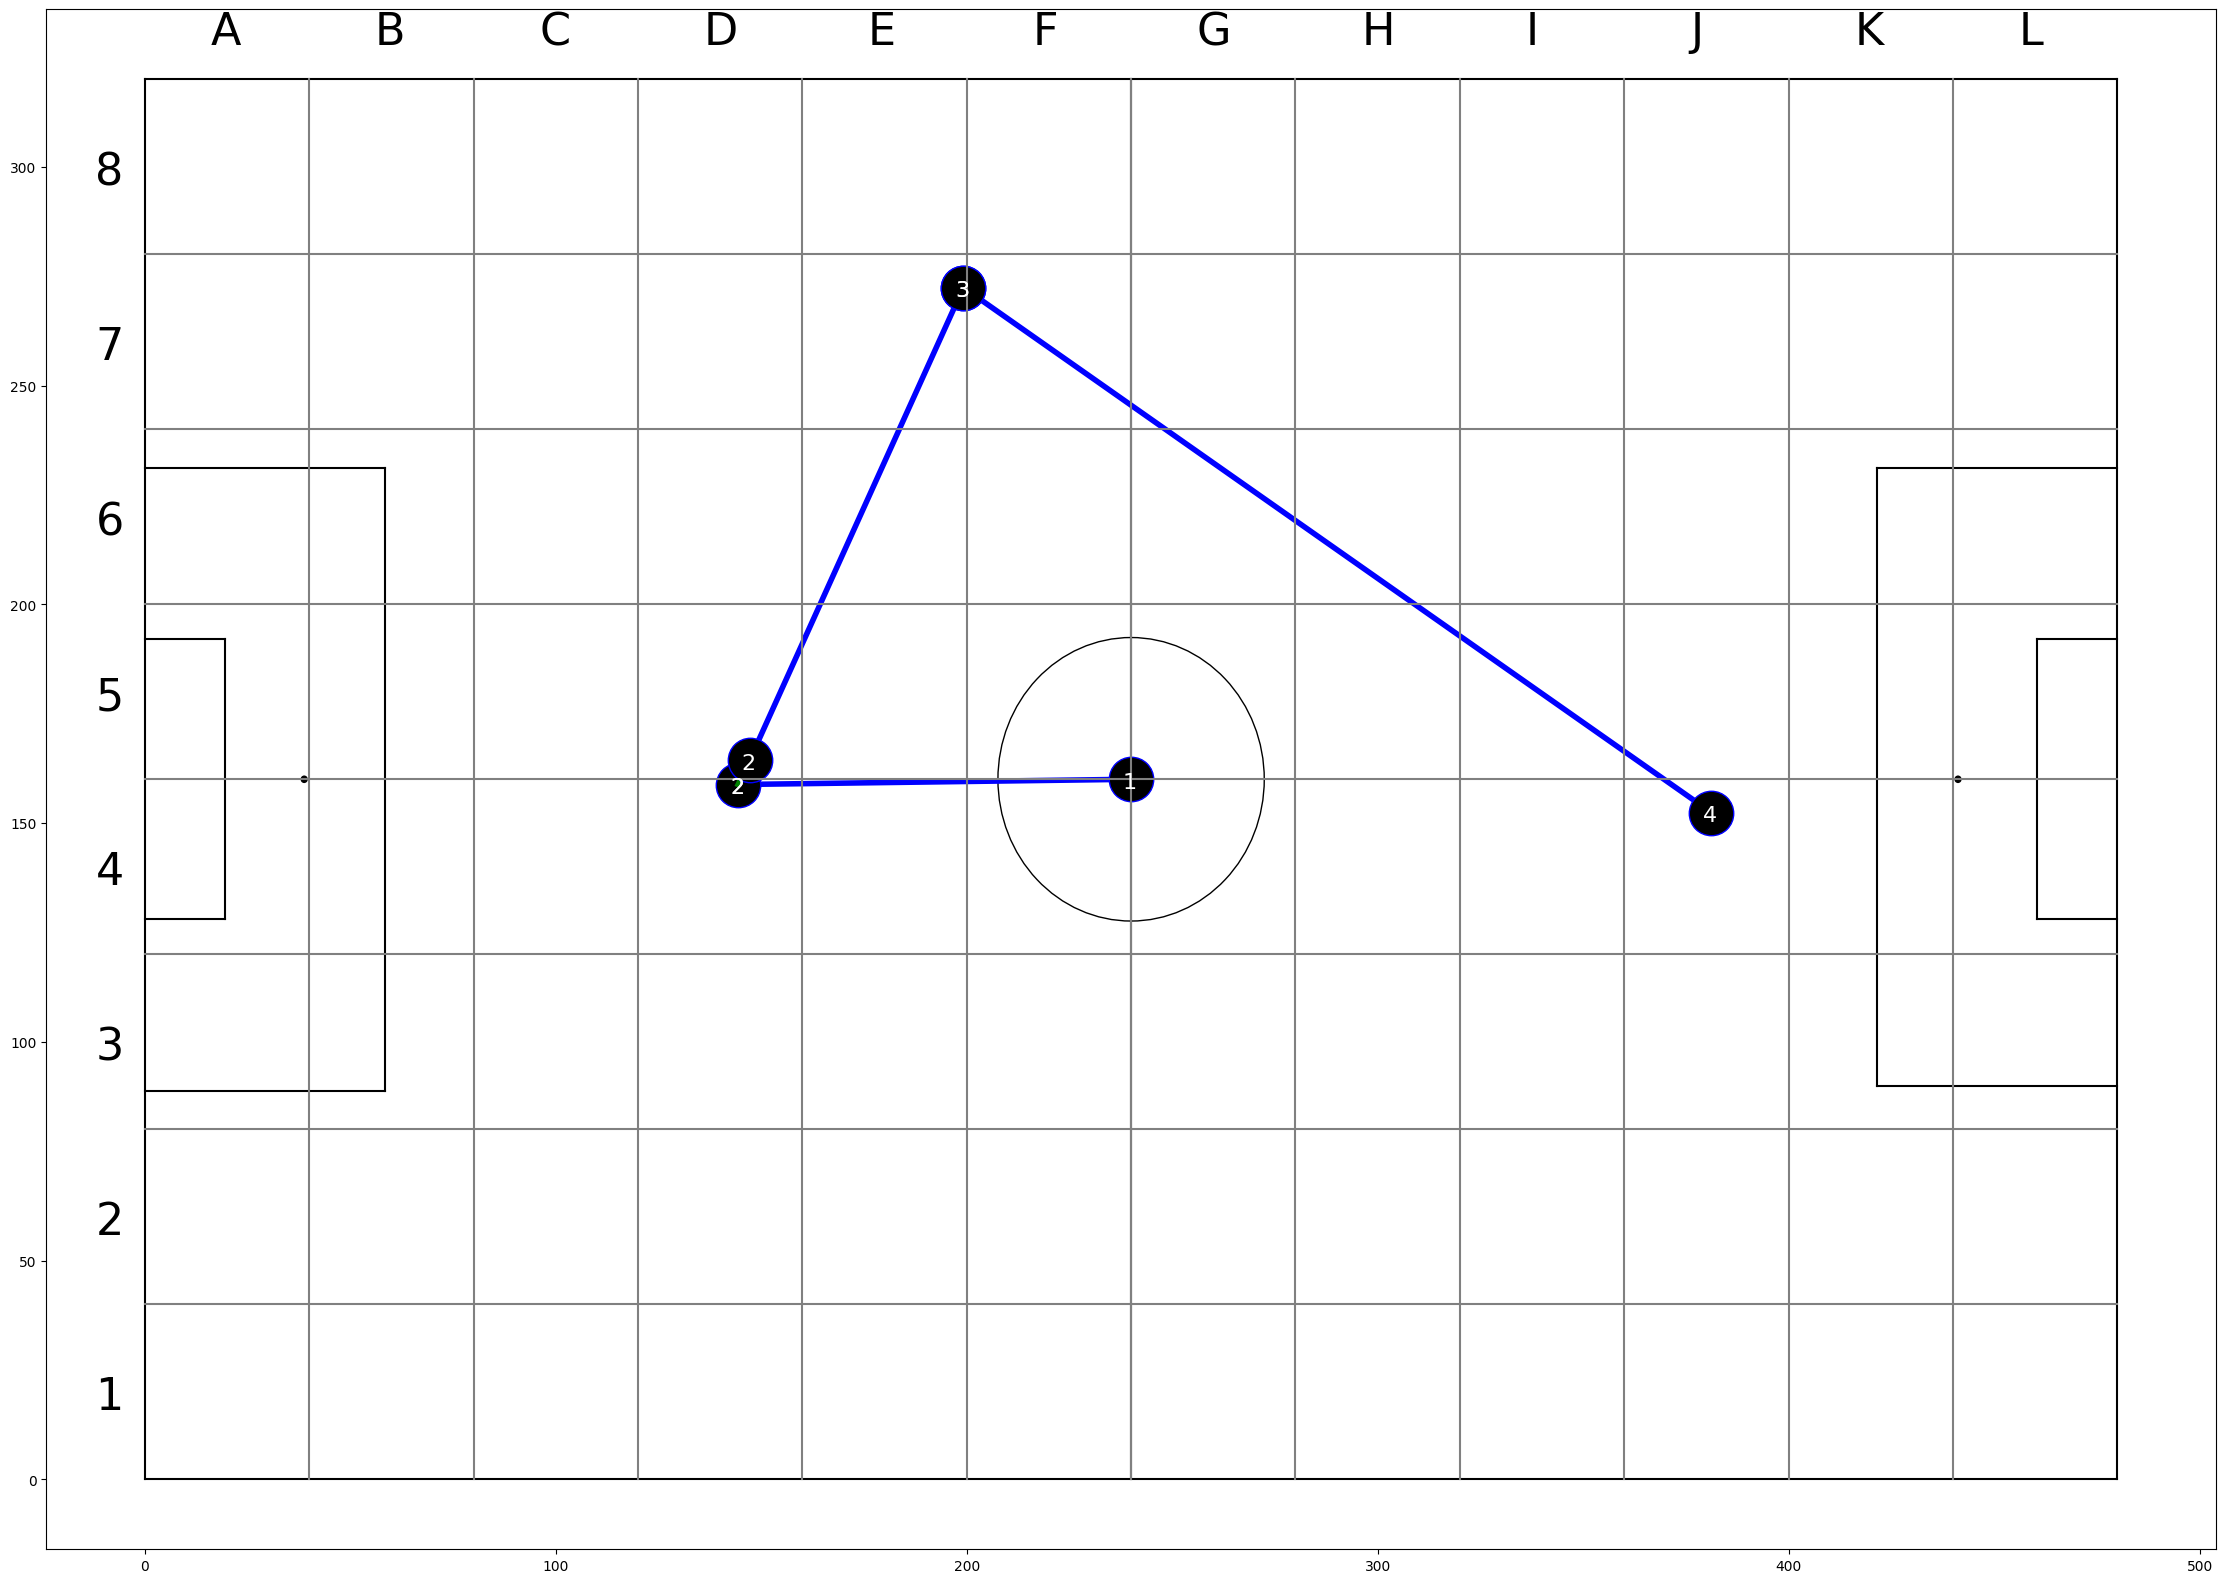

Sequence: 2
Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00

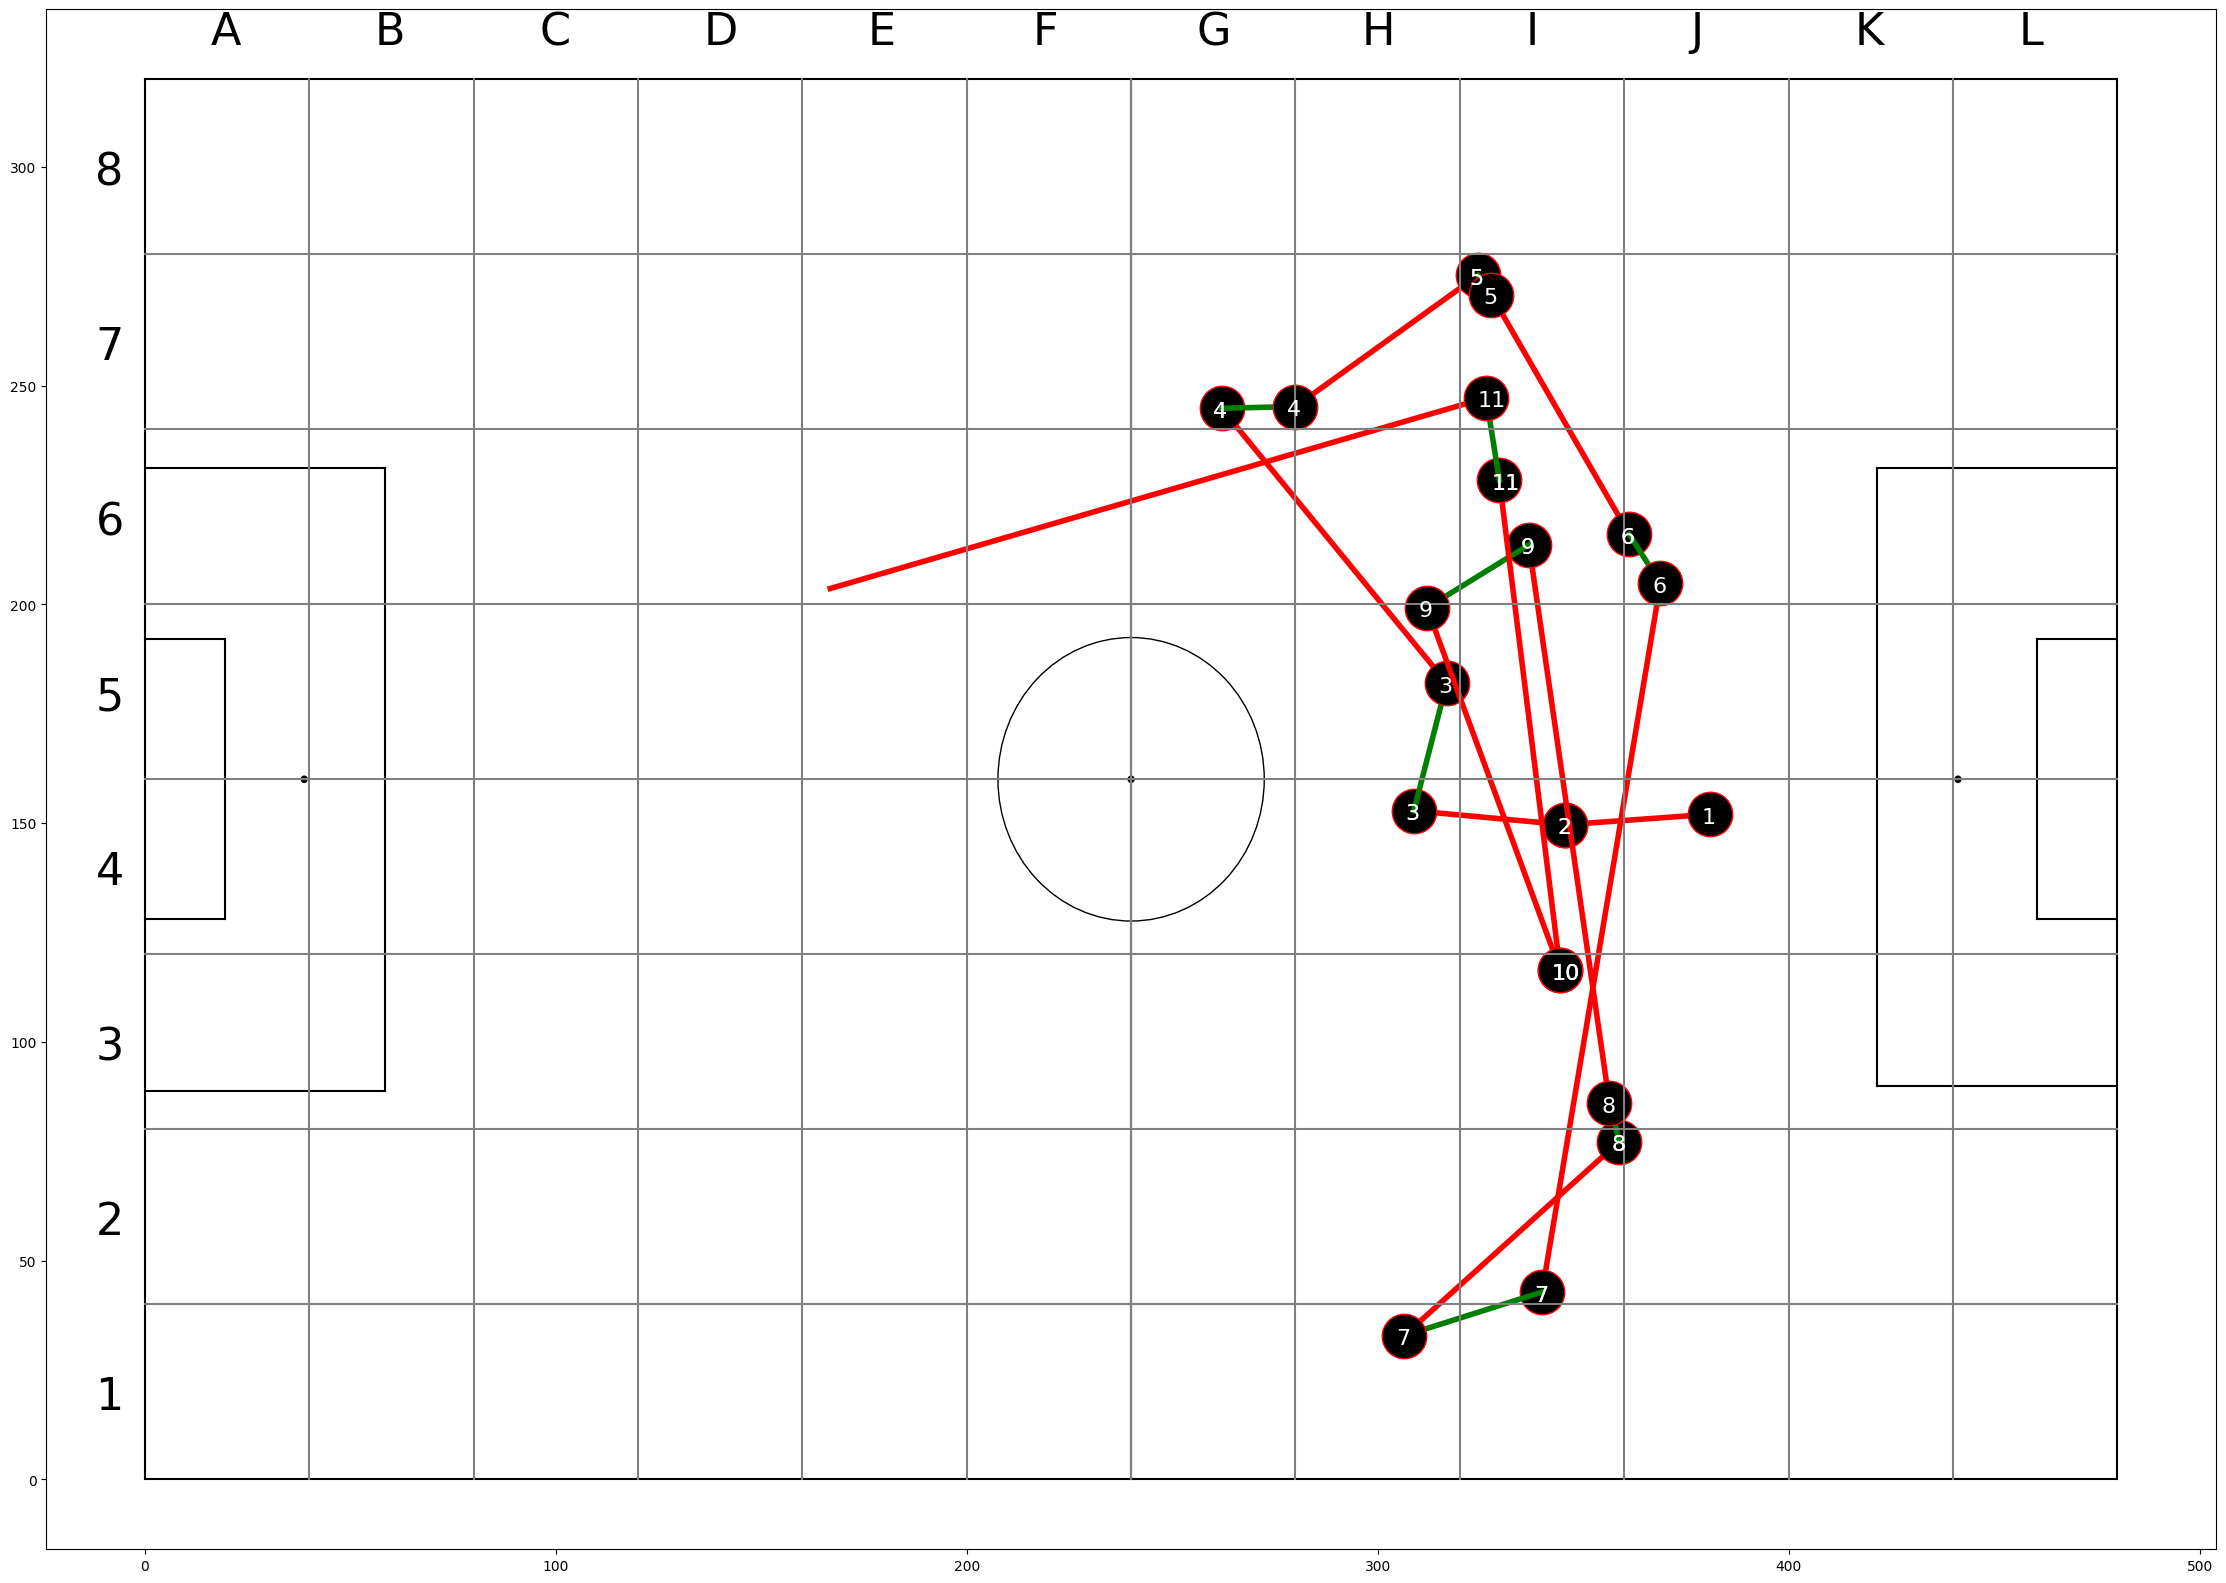

Sequence: 3
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:00:38.375>
2: Kristoffer Olsson (Ball Receipt*) <00:00:39.466>
2: Kristoffer Olsson (Pass) <00:00:39.466>
3: Mikael Lustig (Ball Receipt*) <00:00:40.562>
3: Mikael Lustig (Carry) <00:00:40.562>
3: Mikael Lustig (Pass) <00:00:42.468>


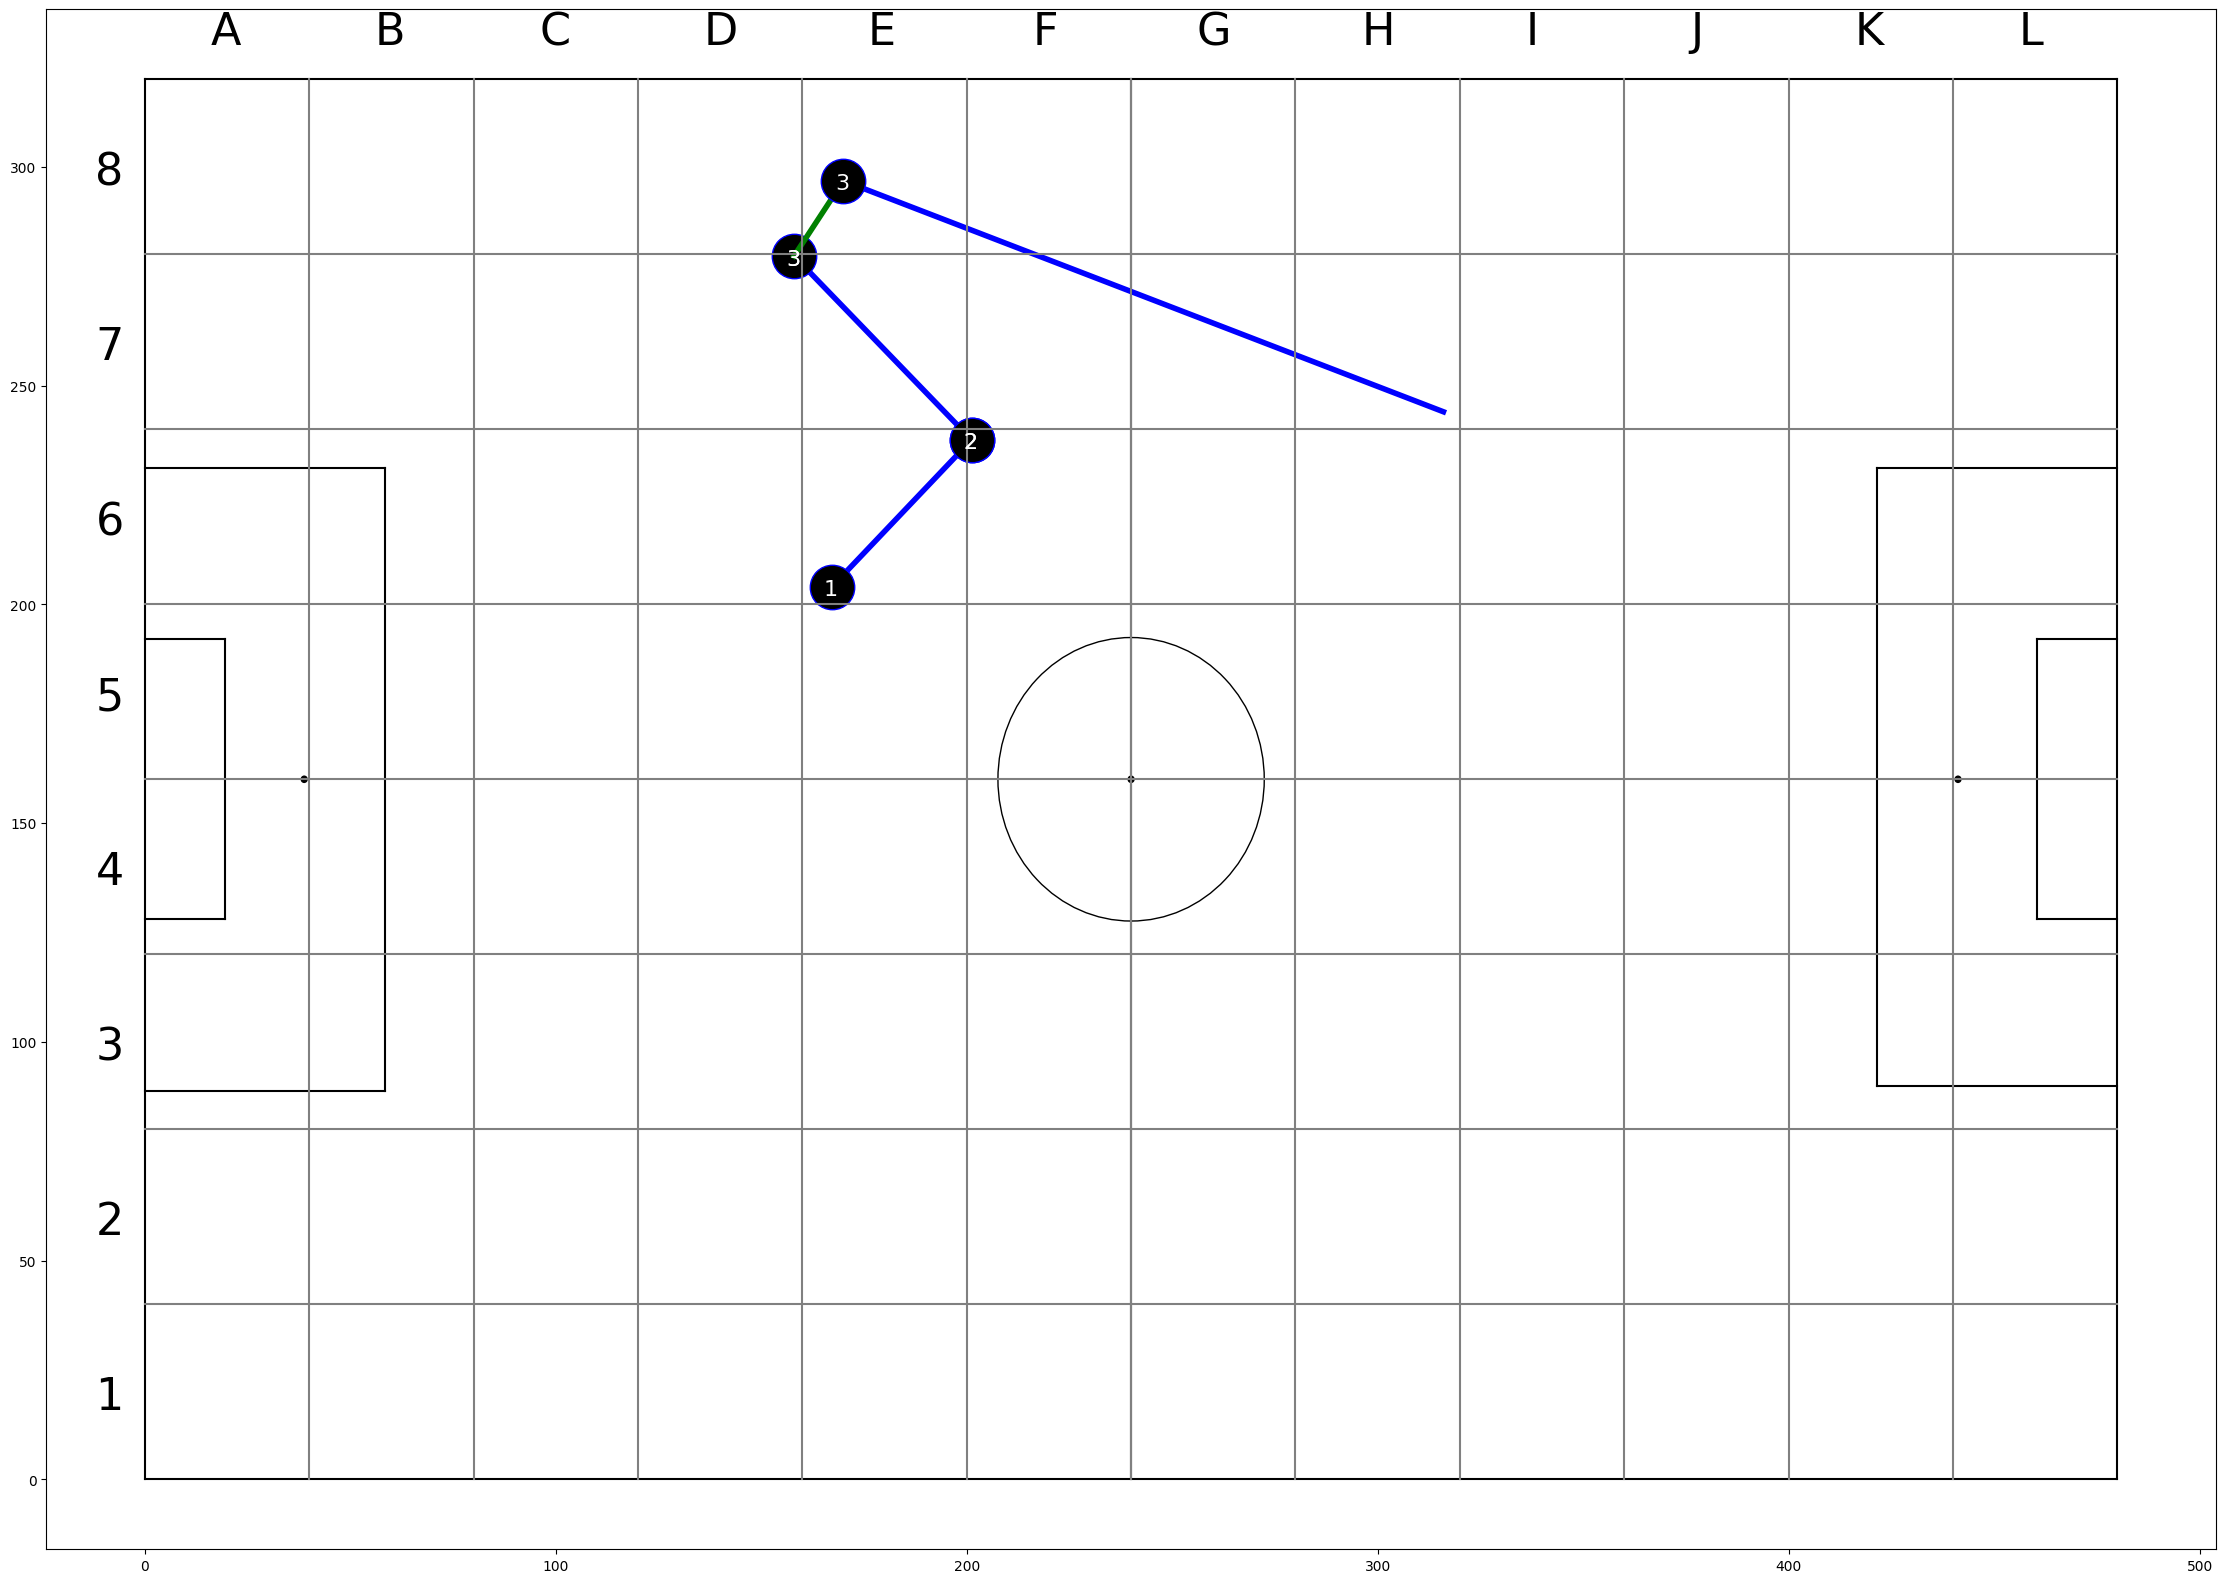

Sequence: 4
Team: Poland
1: Jan Bednarek (Pass) <00:00:44.270>
2: Grzegorz Krychowiak (Ball Receipt*) <00:00:45.101>
2: Grzegorz Krychowiak (Carry) <00:00:45.101>
2: Grzegorz Krychowiak (Pass) <00:00:46.473>
3: Tymoteusz Puchacz (Ball Receipt*) <00:00:47.194>
3: Tymoteusz Puchacz (Carry) <00:00:47.194>
3: Tymoteusz Puchacz (Pass) <00:00:47.847>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:00:48.794>
4: Mateusz Andrzej Klich (Carry) <00:00:48.794>
4: Mateusz Andrzej Klich (Dispossessed) <00:00:50.138>


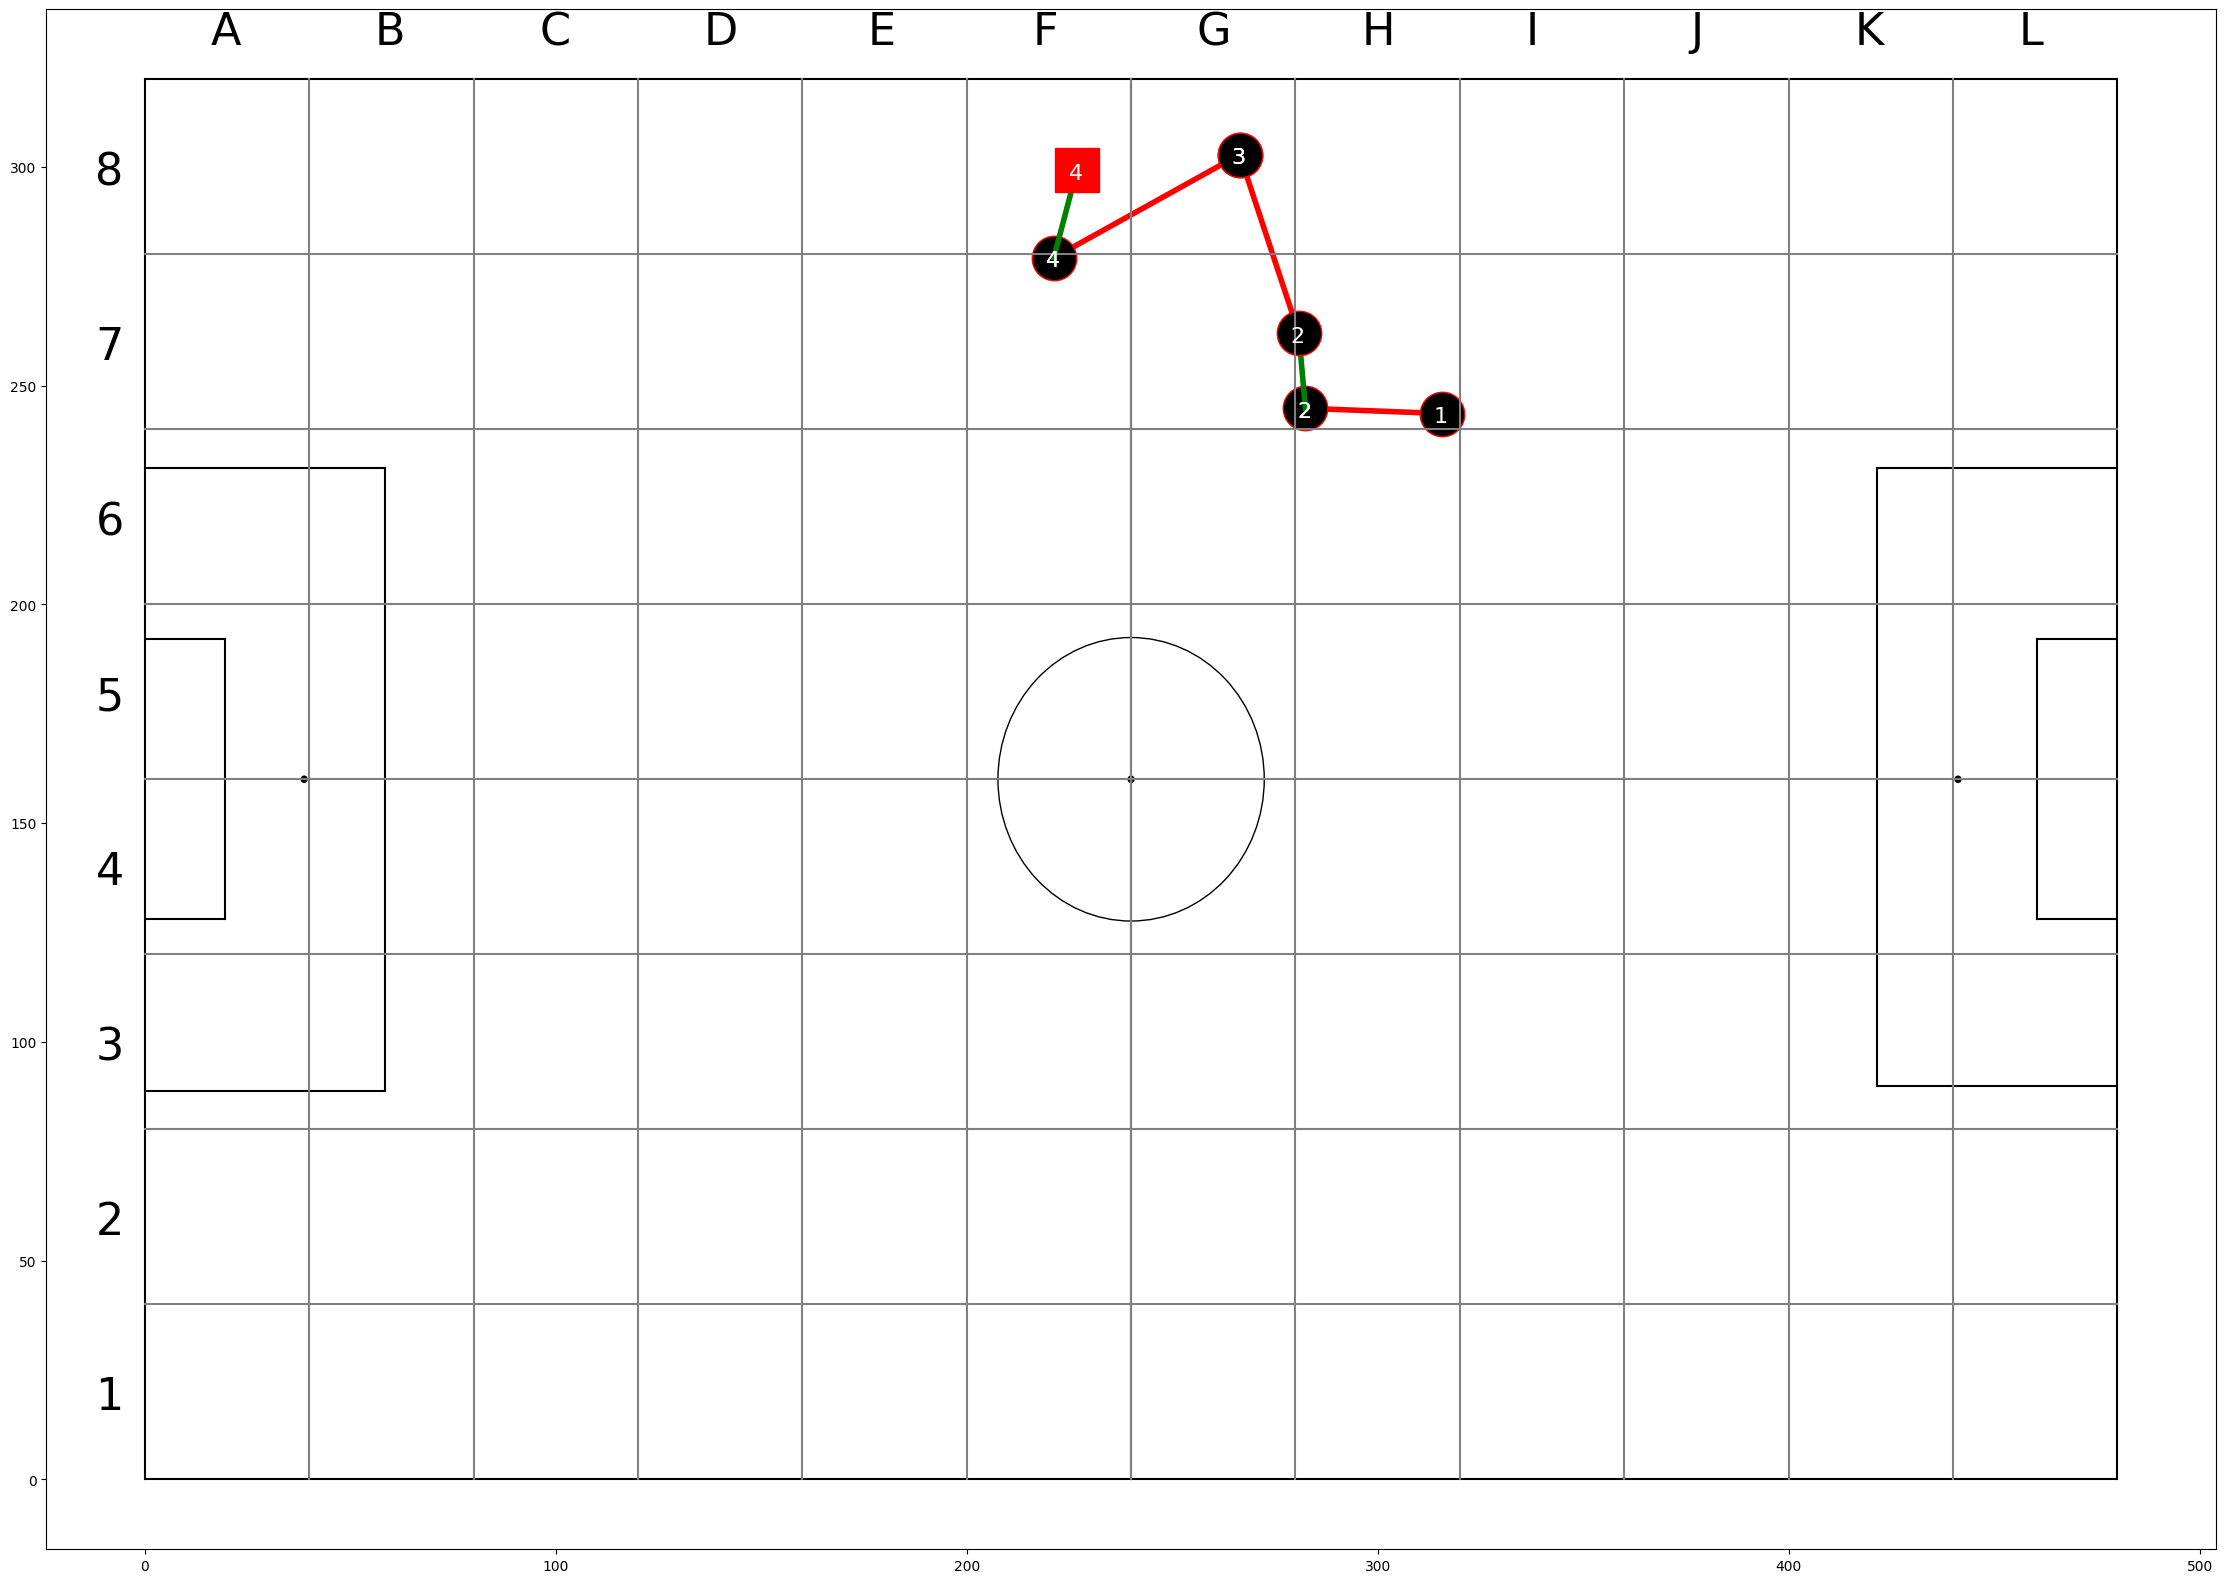

Sequence: 5
Team: Sweden
1: Mikael Lustig (Pass) <00:01:10.498>
2: Sebastian Larsson (Ball Receipt*) <00:01:11.479>
2: Sebastian Larsson (Pass) <00:01:11.479>
3: Mikael Lustig (Ball Receipt*) <00:01:12.472>
3: Mikael Lustig (Pass) <00:01:12.472>
4: Sebastian Larsson (Ball Receipt*) <00:01:13.070>
4: Sebastian Larsson (Pass) <00:01:13.070>
5: Mikael Lustig (Ball Receipt*) <00:01:14.119>
5: Mikael Lustig (Carry) <00:01:14.119>
5: Mikael Lustig (Pass) <00:01:15.083>
6: Alexander Isak (Ball Receipt*) <00:01:16.569>
6: Alexander Isak (Carry) <00:01:16.569>
6: Alexander Isak (Pass) <00:01:16.577>
7: Emil Peter Forsberg (Ball Receipt*) <00:01:17.827>
7: Emil Peter Forsberg (Carry) <00:01:17.827>
7: Emil Peter Forsberg (Pass) <00:01:17.830>
8: Alexander Isak (Ball Receipt*) <00:01:18.888>
8: Alexander Isak (Carry) <00:01:18.888>
8: Alexander Isak (Dispossessed) <00:01:19.168>
9: Emil Peter Forsberg (Pass) <00:01:19.483>
10: Alexander Isak (Ball Receipt*) <00:01:20.025>
10: Alexander Isak (Pass

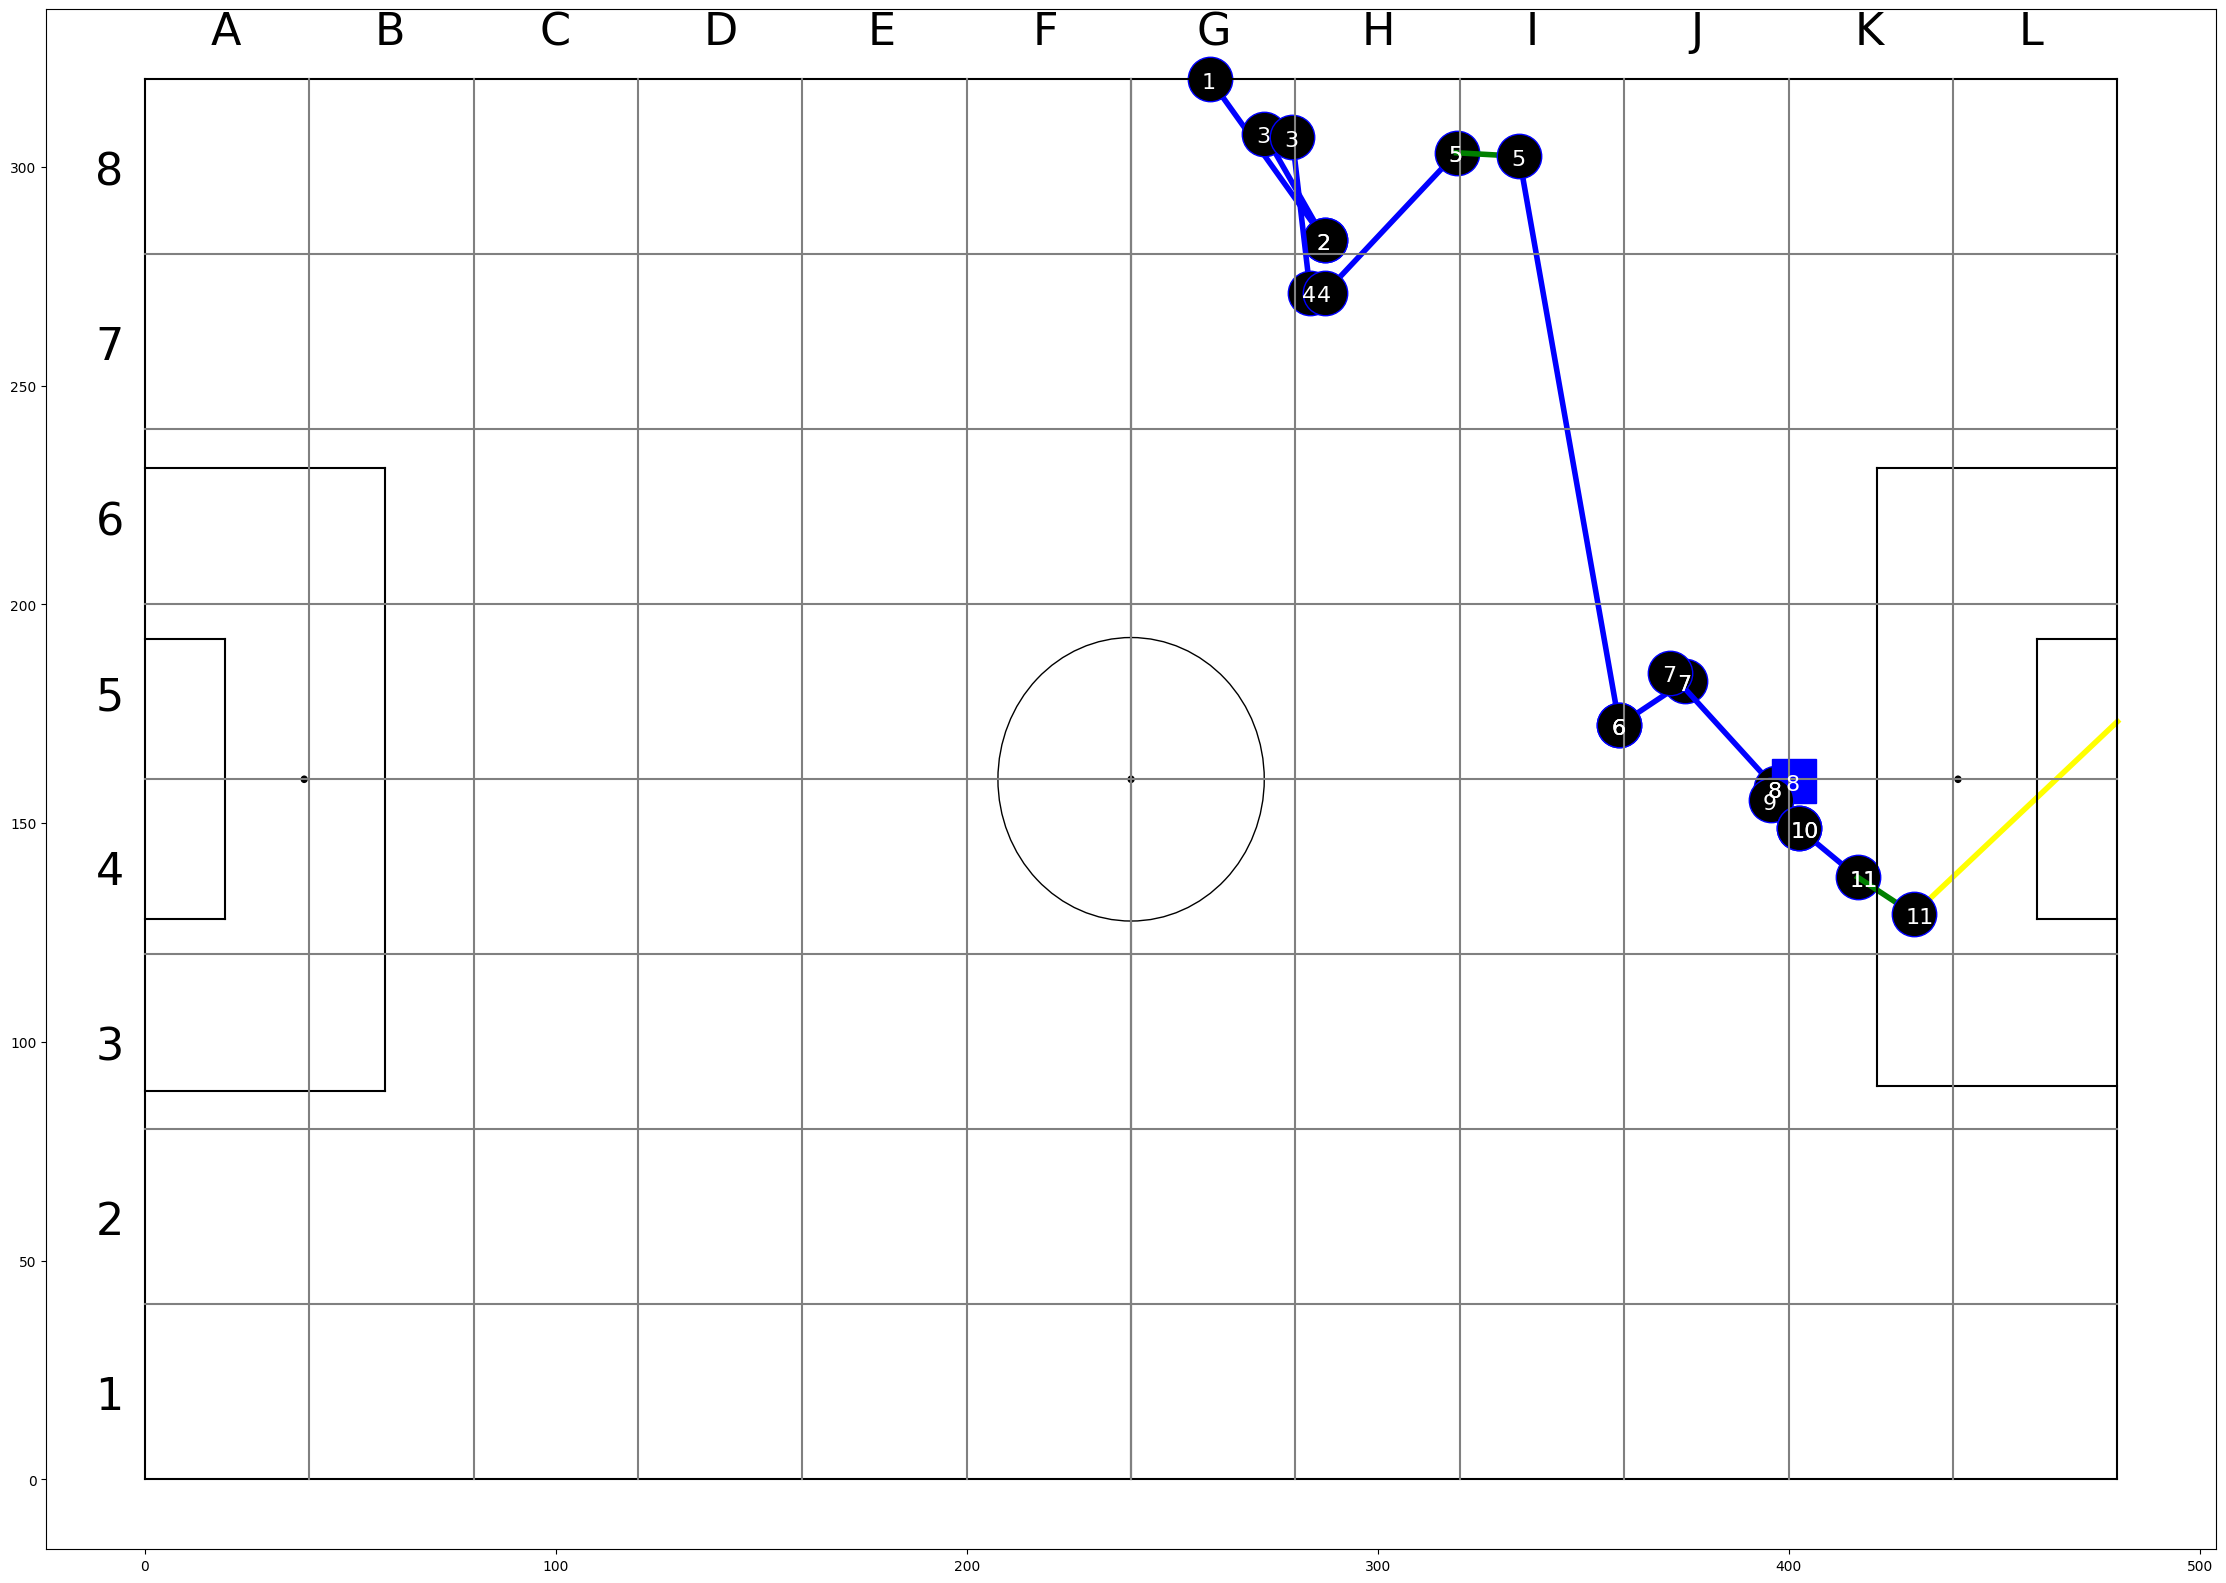

In [11]:
start_team = merged_events['possession_team'][0]

for i, s in enumerate(sequences):
    print(f'Sequence: {i+1}')
    draw_events_sequence2(s, start_team, 12, 8, scale=4)
    if i == 4:
        break